# Домашнее задание 1. Message passing своими руками

**ФИО:** Утюжников Дмитрий Александрович

**Группа:** S4202

Выполнены: части 1–3, бонусы A и B.

## Подготовка окружения

Выполнить все ячейки сверху вниз. Первая ячейка кода установит зависимости.

In [82]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '--disable-pip-version-check',
    'torch', 'torch_geometric', 'pytest', 'numpy',
    'pandas', 'matplotlib', 'scikit-learn', 'ipython',
])
print('Зависимости установлены.')


Зависимости установлены.


In [83]:
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.data import Data
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import subgraph, to_undirected
from sklearn.model_selection import train_test_split
from IPython.display import display
from submission import MyGCNConv, MySAGEConv

torch.set_num_threads(1)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
SEEDS = range(5)
HIDDEN = 64

## Часть 1. Реализация и проверка — 2 балла

- [ ] Реализуйте `MyGCNConv` — слой GCN из лекции 3, через scatter-операции.
- [ ] Реализуйте `MySAGEConv` — mean-агрегация соседей плюс отдельная матрица
      для собственного вектора вершины (без петель).
- [ ] Положите оба класса в `submission.py` и прогоните автотесты:

```bash
pip install pytest torch torch_geometric
pytest tests/test_task1.py -v
```

- [ ] Приложите вывод тестов в ноутбук. **Работа без прохождения тестов не принимается.**

Тесты проверяют совпадение с `GCNConv` и `SAGEConv` из PyG при одинаковых весах,
инвариантность к перенумерации вершин, поведение на направленном графе и на
вершинах без соседей.

In [84]:
result = subprocess.run(
    [sys.executable, '-m', 'pytest', 'tests/test_task1.py', '-v', '-p', 'no:cacheprovider'],
    capture_output=True, text=True,
)
print(result.stdout)
assert result.returncode == 0 and '7 passed' in result.stdout

============================= test session starts ==============================
platform darwin -- Python 3.14.2, pytest-9.2.0, pluggy-1.7.0 -- /Users/dima-utyuz/data_analytics/myenv/bin/python
rootdir: /Users/dima-utyuz/data_analytics/gnn-course-itmo/tasks
plugins: anyio-4.12.1
collecting ... collected 7 items

tests/test_task1.py::test_gcn_output_shape PASSED                        [ 14%]
tests/test_task1.py::test_gcn_matches_pyg PASSED                         [ 28%]
tests/test_task1.py::test_gcn_on_directed_graph PASSED                   [ 42%]
tests/test_task1.py::test_gcn_permutation_invariance PASSED              [ 57%]
tests/test_task1.py::test_gcn_isolated_node_is_finite PASSED             [ 71%]
tests/test_task1.py::test_sage_matches_pyg PASSED                        [ 85%]
tests/test_task1.py::test_gcn_is_trainable PASSED                        [100%]

=============================== warnings summary ===============================
tests/test_task1.py: 35 warnings
  /Users/d

## Часть 2. Воспроизведение результата — 1.5 балла

- [ ] Обучите двухслойную модель на своих слоях на **Cora** и **CiteSeer**,
      стандартный сплит Planetoid.
- [ ] Каждый замер — **не менее 5 запусков с разными сидами**, в отчёте среднее и
      стандартное отклонение.
- [ ] Сравните с числами из статьи Kipf & Welling (2017): Cora 81.5, CiteSeer 70.3.
      Попадание в ± 2 процентных пункта считается воспроизведением.
- [ ] Обязательный baseline: MLP того же размера, который не видит графа.
      Насколько граф улучшает результат на каждом датасете?

In [85]:
datasets = {}
for name in ['Cora', 'CiteSeer']:
    data = Planetoid(root=str(Path(tempfile.gettempdir()) / 'gnn-task1-work' / 'data'),
                     name=name, split='public')[0]
    data.edge_index = to_undirected(data.edge_index)
    datasets[name] = data.to(device)

In [86]:
class GNN(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, layers=2, conv=MyGCNConv, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden] * (layers - 1) + [out_dim]
        self.convs = nn.ModuleList([conv(dims[i], dims[i + 1]) for i in range(layers)])
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        hidden = None
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
                hidden = x
                x = F.dropout(x, p=self.dropout, training=self.training)
        return (x, hidden) if return_hidden else x


class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden)
        self.lin2 = nn.Linear(hidden, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.lin2(x)


def make_model(data, name='GCN', layers=2):
    dims = (data.num_features, HIDDEN, int(data.y.max()) + 1)
    if name == 'MLP':
        return MLP(*dims).to(device)
    conv = MyGCNConv if name == 'GCN' else MySAGEConv
    return GNN(*dims, layers=layers, conv=conv).to(device)


def accuracy(logits, data, mask):
    return float((logits.argmax(1)[mask] == data.y[mask]).float().mean())


def fit(model, data, epochs=200, lr=0.01, weight_decay=5e-4, patience=30):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_state, waiting = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        opt.zero_grad()
        logits = model(data.x, data.edge_index)
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            val = accuracy(model(data.x, data.edge_index), data, data.val_mask)
        if val > best_val:
            best_val, waiting = val, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waiting += 1
            if waiting >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()


def mean_std(values):
    values = np.asarray(values)
    return f'{values.mean():.2f} ± {values.std(ddof=0):.2f}'

In [87]:
standard_rows = []
for name, data in datasets.items():
    for model_name in ['GCN', 'SAGE', 'MLP']:
        for seed in SEEDS:
            torch.manual_seed(seed)
            model = make_model(data, model_name)
            fit(model, data)
            with torch.no_grad():
                acc = 100 * accuracy(model(data.x, data.edge_index), data, data.test_mask)
            standard_rows.append(dict(dataset=name, model=model_name, seed=seed, accuracy=acc))

standard = pd.DataFrame(standard_rows)
print('Accuracy в процентах (%): среднее ± стандартное отклонение по 5 сидам.')
display(standard.groupby(['dataset', 'model']).accuracy.apply(mean_std)
        .rename('Accuracy, %: среднее ± std').unstack('model'))
reference = {'Cora': 81.5, 'CiteSeer': 70.3}
for name in datasets:
    results = standard.query('dataset == @name').pivot(index='seed', columns='model', values='accuracy')
    difference = results.GCN.mean() - reference[name]
    print(f'{name}: GCN − MLP = {mean_std(results.GCN - results.MLP)} п.п.; '
          f'отклонение от {reference[name]}%: {difference:+.2f} п.п.; '
          f'воспроизведение: {abs(difference) <= 2}')

Accuracy в процентах (%): среднее ± стандартное отклонение по 5 сидам.


model,GCN,MLP,SAGE
dataset,,,
CiteSeer,68.60 ± 0.29,54.30 ± 0.38,67.06 ± 1.41
Cora,79.78 ± 0.47,56.76 ± 0.56,79.00 ± 0.52


Cora: GCN − MLP = 23.02 ± 0.79 п.п.; отклонение от 81.5%: -1.72 п.п.; воспроизведение: True
CiteSeer: GCN − MLP = 14.30 ± 0.32 п.п.; отклонение от 70.3%: -1.70 п.п.; воспроизведение: True


## Часть 3. Что ломается при увеличении глубины — 1.5 балла

- [ ] Обучите модель с 2, 4, 8 и 16 слоями, постройте график accuracy от глубины.
- [ ] Численно измерьте, насколько представления вершин стали похожи друг на друга:
      среднее попарное косинусное сходство скрытого слоя (или Dirichlet energy).
- [ ] Постройте график этой величины от числа слоёв рядом с графиком accuracy.
- [ ] **Объясните в тексте**, что именно произошло. Различайте два случая: представления
      слиплись (сходство близко к 1) и сеть просто не обучилась (активации занулились).

Test и Train — accuracy в процентах (%). В таблице: среднее ± стандартное отклонение по 5 сидам.


,"Test, %","Train, %",Косинус,Норма,"Нулевые векторы, %"
layers,,,,,
2,79.78 ± 0.47,98.57 ± 1.01,0.74 ± 0.01,4.15e+00 ± 9.97e-01,0.00 ± 0.00
4,78.54 ± 0.77,99.57 ± 0.57,0.58 ± 0.04,1.71e+01 ± 2.93e+00,0.00 ± 0.00
8,28.68 ± 7.13,17.57 ± 2.15,0.91 ± 0.02,4.62e-05 ± 9.25e-05,0.00 ± 0.00
16,31.10 ± 0.80,14.29 ± 0.90,0.98 ± 0.02,1.30e-08 ± 2.60e-08,0.00 ± 0.00


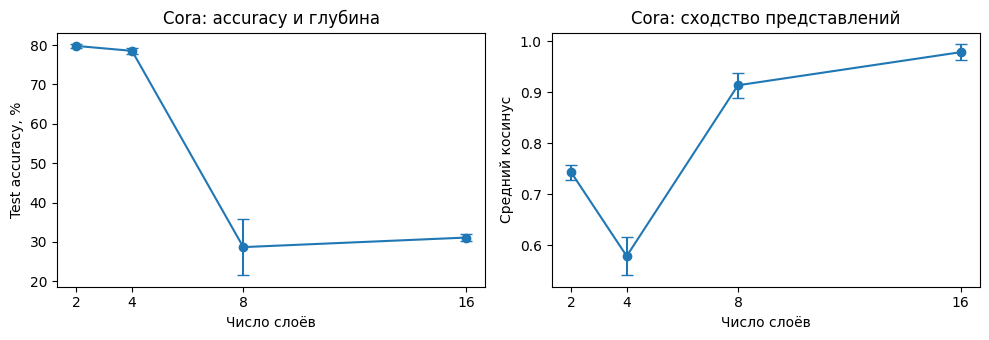

In [88]:
def hidden_diagnostics(hidden):
    h = hidden.double()
    norms = h.norm(dim=1)
    nonzero = norms > 0
    h[nonzero] = h[nonzero] / norms[nonzero].unsqueeze(-1)
    sim = h @ h.T
    n = h.size(0)
    cosine = float((sim.sum() - sim.diag().sum()) / (n * (n - 1)))
    return dict(cosine=cosine, mean_norm=float(norms.mean()),
                zero_pct=100 * float((hidden == 0).all(dim=1).float().mean()))

data = datasets['Cora']
depth_rows = []
for layers in [2, 4, 8, 16]:
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = make_model(data, 'GCN', layers=layers)
        fit(model, data)
        with torch.no_grad():
            logits, hidden = model(data.x, data.edge_index, return_hidden=True)
            depth_rows.append(dict(layers=layers,
                test_acc=100 * accuracy(logits, data, data.test_mask),
                train_acc=100 * accuracy(logits, data, data.train_mask),
                **hidden_diagnostics(hidden)))

depth = pd.DataFrame(depth_rows)
table = depth.groupby('layers').agg({
    'test_acc': mean_std, 'train_acc': mean_std, 'cosine': mean_std,
    'mean_norm': lambda s: f'{s.mean():.2e} ± {s.std(ddof=0):.2e}',
    'zero_pct': mean_std,
})
print('Test и Train — accuracy в процентах (%). В таблице: среднее ± стандартное отклонение по 5 сидам.')
display(table.rename(columns={'test_acc': 'Test, %', 'train_acc': 'Train, %',
    'cosine': 'Косинус', 'mean_norm': 'Норма', 'zero_pct': 'Нулевые векторы, %'}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric, title, ylabel in zip(axes, ['test_acc', 'cosine'],
        ['Cora: accuracy и глубина', 'Cora: сходство представлений'],
        ['Test accuracy, %', 'Средний косинус']):
    groups = depth.groupby('layers')[metric]
    ax.errorbar([2, 4, 8, 16], groups.mean(), yerr=groups.std(ddof=0), marker='o', capsize=4)
    ax.set(title=title, xlabel='Число слоёв', ylabel=ylabel, xticks=[2, 4, 8, 16])
plt.tight_layout()
plt.show()

При 8 и 16 слоях косинус достигает 0.91 и 0.98: представления слипаются.
Одновременно train accuracy падает до 17.57% и 14.29%, а нормы векторов —
до $4.6\cdot10^{-5}$ и $1.3\cdot10^{-8}$: сеть плохо обучается, активации затухают.
Полностью нулевых векторов нет. Нулевой косинус при нулевых активациях означал бы
сбой обучения, а не отсутствие сглаживания.

## Бонус A. Inductive-режим — 2.5 балла

Проверяем, умеет ли модель считать векторы для вершин, которых не видела при обучении.

- [ ] Отложите «новые» вершины — 1000 вершин стандартного `test_mask`. Уберите из графа и их
      самих, и все их рёбра (`torch_geometric.utils.subgraph`): получится обучающий подграф.
- [ ] **Inductive:** обучите двухслойную модель на `MySAGEConv` только на подграфе. Затем без
      переобучения прогоните её по полному графу — новые вершины приходят вместе со своими
      рёбрами — и посчитайте accuracy на новых вершинах.
- [ ] **Transductive:** обучите ту же модель на полном графе — видны все вершины и рёбра, метки
      только у обучающих вершин — и посчитайте accuracy на тех же новых вершинах.
- [ ] Сведите результат в таблицу: по 5 сидов на режим, среднее ± стандартное отклонение.

| Режим | Видела ли модель новые вершины при обучении? | Accuracy на новых вершинах |
|---|---|:--:|
| inductive | нет | … ± … |
| transductive | да, но без меток | … ± … |

- [ ] Объясните в 2–3 предложениях, насколько дорого обходится то, что модель не видела
      новые вершины, и откуда берётся эта разница.

> **Ловушка:** если обучать на полном графе и просто прятать метки новых вершин, получится
> transductive, а не inductive. В inductive-режиме при обучении не должно быть ни самих новых
> вершин, ни их рёбер.

In [89]:
full = datasets['Cora']
new_nodes = full.test_mask.nonzero(as_tuple=True)[0][:1000]
assert new_nodes.numel() == 1000
new_mask = torch.zeros_like(full.test_mask)
new_mask[new_nodes] = True
keep = (~new_mask).nonzero(as_tuple=False).flatten()
edges, _ = subgraph(keep, full.edge_index, relabel_nodes=True, num_nodes=full.num_nodes)
inductive_data = Data(x=full.x[keep], y=full.y[keep], edge_index=edges,
                     train_mask=full.train_mask[keep], val_mask=full.val_mask[keep])

rows = []
for mode, train_data in [('inductive', inductive_data), ('transductive', full)]:
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = make_model(full, 'SAGE')
        fit(model, train_data)
        with torch.no_grad():
            acc = 100 * accuracy(model(full.x, full.edge_index), full, new_mask)
        rows.append(dict(mode=mode, seed=seed, accuracy=acc))

inductive = pd.DataFrame(rows)
display(pd.DataFrame([
    {'Режим': mode, 'Видела новые вершины?': seen,
     'Accuracy, %: среднее ± std': mean_std(inductive.query('mode == @mode').accuracy)}
    for mode, seen in [('inductive', 'нет'), ('transductive', 'да, без меток')]
]))
paired = inductive.pivot(index='seed', columns='mode', values='accuracy')
print('Transductive − inductive:', mean_std(paired.transductive - paired.inductive), 'п.п.')

,Режим,Видела новые вершины?,"Accuracy, %: среднее ± std"
0,inductive,нет,77.86 ± 1.14
1,transductive,"да, без меток",79.00 ± 0.52


Transductive − inductive: 1.14 ± 1.20 п.п.


Отсутствие новых вершин при обучении стоило в среднем 1.14 п.п.
В подграфе меньше соседей, поэтому меняются агрегаты, на которых обучаются веса.
GraphSAGE применяет общую функцию к новым вершинам без переобучения.

## Бонус B. Сколько разметки нужно графу — 2.5 балла

- [ ] Постройте зависимость accuracy от доли размеченных вершин: 1%, 5%, 20%, 60%.
- [ ] На одном графике — GCN и MLP.
- [ ] Ответьте: при какой доле разметки преимущество графа исчезает и почему.

Cora: 60% вершин — пул обучения, 20% — валидация, 20% — тест.
Доли разметки считаются от всех вершин; каждая выборка берётся из исходного пула.
В пределах сида валидация и тест фиксированы, у GCN и MLP маски одинаковы.
Все таблицы и усы графиков показывают среднее ± стандартное отклонение по 5 сидам.

Accuracy в процентах (%): среднее ± стандартное отклонение по 5 сидам.


model,GCN,MLP
fraction,,
1.0,69.74 ± 0.88,46.20 ± 1.71
5.0,81.48 ± 1.80,58.08 ± 1.15
20.0,86.01 ± 0.79,69.00 ± 1.41
60.0,87.90 ± 1.46,75.98 ± 1.07


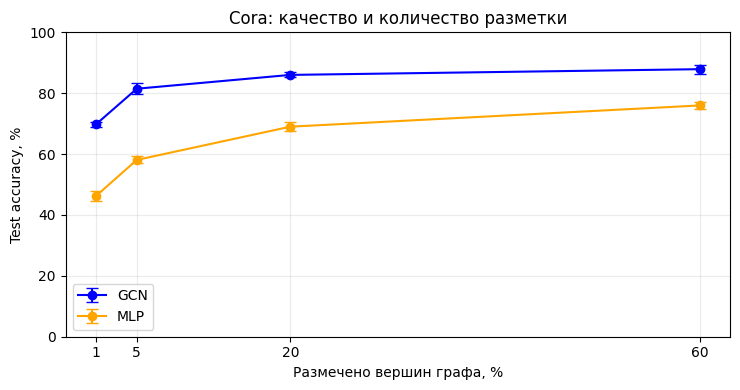

,"GCN − MLP, п.п."
fraction,
1.0,23.54 ± 1.56
5.0,23.39 ± 2.18
20.0,17.01 ± 2.17
60.0,11.92 ± 1.88


In [90]:
fractions = [0.01, 0.05, 0.20, 0.60]
label_rows = []
data = datasets['Cora']
y_cpu = data.y.cpu().numpy()
all_nodes = np.arange(data.num_nodes)

for seed in SEEDS:
    pool, holdout = train_test_split(all_nodes, train_size=0.60, random_state=seed, stratify=y_cpu)
    val_nodes, test_nodes = train_test_split(holdout, test_size=0.5, random_state=seed,
                                           stratify=y_cpu[holdout])
    train_sets = {0.60: pool}
    for fraction in [0.01, 0.05, 0.20]:
        train_sets[fraction], _ = train_test_split(
            pool, train_size=int(fraction * data.num_nodes),
            random_state=seed, stratify=y_cpu[pool])

    def make_mask(nodes):
        mask = torch.zeros(data.num_nodes, dtype=torch.bool, device=device)
        mask[torch.as_tensor(nodes, device=device)] = True
        return mask

    for fraction in fractions:
        split_data = Data(x=data.x, y=data.y, edge_index=data.edge_index,
                          train_mask=make_mask(train_sets[fraction]),
                          val_mask=make_mask(val_nodes), test_mask=make_mask(test_nodes))
        for model_name in ['GCN', 'MLP']:
            torch.manual_seed(seed)
            model = make_model(split_data, model_name)
            fit(model, split_data)
            with torch.no_grad():
                acc = 100 * accuracy(model(split_data.x, split_data.edge_index),
                                     split_data, split_data.test_mask)
            label_rows.append(dict(fraction=100 * fraction, model=model_name,
                                   seed=seed, accuracy=acc))


labels = pd.DataFrame(label_rows)
print('Accuracy в процентах (%): среднее ± стандартное отклонение по 5 сидам.')
display(labels.groupby(['fraction', 'model']).accuracy.apply(mean_std).unstack('model'))
fig, ax = plt.subplots(figsize=(7.5, 4))
for model_name, color in [('GCN', 'blue'), ('MLP', 'orange')]:
    groups = labels.query('model == @model_name').groupby('fraction').accuracy
    ax.errorbar([1, 5, 20, 60], groups.mean(), yerr=groups.std(ddof=0),
                marker='o', capsize=4, color=color, label=model_name)
ax.set(title='Cora: качество и количество разметки', xlabel='Размечено вершин графа, %',
       ylabel='Test accuracy, %', xticks=[1, 5, 20, 60], ylim=(0, 100))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

paired = labels.pivot(index=['fraction', 'seed'], columns='model', values='accuracy')
gaps = (paired.GCN - paired.MLP).groupby('fraction')
display(gaps.apply(mean_std).rename('GCN − MLP, п.п.').to_frame())

На проверенных долях 1%, 5%, 20%, 60% преимущество GCN не исчезло:
разрыв сократился с 23.54 до 11.92 п.п. Больше меток помогает MLP учиться
по признакам, но граф сохраняет дополнительную информацию.